# PreTest 01: Binary Classification แบบครบวงจร — การพยากรณ์ฝนตกในวันถัดไป
### จากข้อมูลดิบ → ทำความสะอาด → Visualization → เตรียมข้อมูล → เทรน 3 โมเดล → วัดผล → เลือกโมเดล

> **ที่มา:** ดัดแปลงและขยายจาก Kaggle Notebook
> [Logistic Regression Classifier Tutorial](https://www.kaggle.com/code/prashant111/logistic-regression-classifier-tutorial) โดย Prashant Banerjee
> สิ่งที่เพิ่ม/แก้: คำอธิบายภาษาไทยทุกขั้นตอน, ลบแถวที่ Target หาย, แก้การอ่าน Confusion Matrix ให้ถูกต้อง,
> คำนวณขอบ Outlier จาก Train Set เท่านั้น, เพิ่มโมเดล **Decision Tree** และ **Random Forest**, ตารางเปรียบเทียบ 3 โมเดล
>
> **ชุดข้อมูล (Dataset):** [Rain in Australia](https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package) — ข้อมูลอากาศรายวัน ~10 ปี จาก 49 เมืองในออสเตรเลีย

---

## ภาพรวมขั้นตอน (สามารถใช้เป็นโครงสร้างในการทำข้อสอบได้)

| ขั้น | งาน | คำถามที่ต้องตอบ |
|---|---|---|
| 1 | กำหนดโจทย์ | ทำนายอะไร? เป็น Classification หรือ Regression? วัดผลด้วยอะไร? |
| 2 | โหลดข้อมูล | ข้อมูลมีกี่แถว กี่คอลัมน์? |
| 3 | สำรวจข้อมูลเบื้องต้น | แต่ละคอลัมน์คืออะไร ชนิดข้อมูลถูกหรือไม่ |
| 4 | ทำความสะอาด (Data Cleaning) | Target หายหรือไม่ ซ้ำหรือไม่ ค่าหายเท่าใด |
| 5 | EDA & Visualization | Target สมดุลหรือไม่ มี Outlier หรือไม่ ตัวแปรไหนสัมพันธ์กับ Target? |
| 6 | เตรียมข้อมูล (Preprocessing) | Split → จัดการ Outlier → เติมค่าหาย → Encode → Scale |
| 7–9 | เทรนโมเดล 3 ตัว | Logistic Regression, Decision Tree, Random Forest |
| 10 | เปรียบเทียบและเลือกโมเดล | ตัวไหนดีที่สุด เพราะอะไร? |

> **หลักการสำคัญ:** ทุกอย่างที่ "เรียนรู้จากข้อมูล" (ค่า median, mode, ขอบ outlier, min/max ของ scaler)
> ต้องคำนวณจาก **Train Set เท่านั้น** แล้วค่อยนำไปใช้กับ Test Set (มิฉะนั้นจะเกิด Data Leakage)

---
# ขั้นที่ 1: กำหนดโจทย์ (Problem Definition)

- **เป้าหมาย:** ใช้ข้อมูลอากาศ **วันนี้** ทำนายว่า **พรุ่งนี้ฝนจะตกหรือไม่** (`RainTomorrow` = Yes / No)
- **ประเภทปัญหา:** Target มีเพียง 2 ค่า → **Binary Classification**
- **วัดผลด้วย:** Accuracy, Precision, Recall, F1-score, ROC-AUC (จะอธิบายทีละตัวในขั้นที่ 7)

---
# ขั้นที่ 2: นำเข้าไลบรารีและโหลดข้อมูล

In [35]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', 50)
sns.set_theme(style="whitegrid")

โค้ดด้านล่างจะหาไฟล์ในโฟลเดอร์ `Data/` ก่อน ถ้าไม่มี (เช่นเปิดบน Google Colab) จะดาวน์โหลดจาก Kaggle ให้อัตโนมัติด้วย `kagglehub`

In [36]:
DATA_FILE = "Data/weatherAUS.csv"

if not os.path.exists(DATA_FILE):
    import kagglehub
    folder = kagglehub.download_dataset("jsphyg/weather-dataset-rattle-package", DATA_FILE)
    DATA_FILE = os.path.join(folder, DATA_FILE)

df = pd.read_csv(DATA_FILE)
print(f"Data shape: {df.shape}")

Data shape: (145460, 23)


---
# ขั้นที่ 3: สำรวจข้อมูลเบื้องต้น (First Look)
### 3.1 ดูตัวอย่างข้อมูล 5 แถวแรก

In [37]:
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


### 3.2 ความหมายของแต่ละคอลัมน์ (Data Dictionary)

| คอลัมน์ | ความหมาย | ชนิด |
|---|---|---|
| `Date` | วันที่ | ข้อความ (ต้องแปลง) |
| `Location` | เมืองที่วัด (49 เมือง) | Categorical |
| `MinTemp`, `MaxTemp` | อุณหภูมิต่ำสุด/สูงสุด (°C) | Numerical |
| `Rainfall` | ปริมาณฝนวันนี้ (มม.) | Numerical |
| `Evaporation` | ปริมาณการระเหย (มม.) | Numerical |
| `Sunshine` | จำนวนชั่วโมงแดด | Numerical |
| `WindGustDir`, `WindGustSpeed` | ทิศ/ความเร็วลมกระโชกแรงสุด | Cat / Num |
| `WindDir9am`, `WindDir3pm` | ทิศลมตอน 9 โมง / บ่าย 3 | Categorical |
| `WindSpeed9am`, `WindSpeed3pm` | ความเร็วลม (กม./ชม.) | Numerical |
| `Humidity9am`, `Humidity3pm` | ความชื้น (%) | Numerical |
| `Pressure9am`, `Pressure3pm` | ความกดอากาศ (hPa) | Numerical |
| `Cloud9am`, `Cloud3pm` | ปริมาณเมฆ (0–8 ส่วน) | Numerical |
| `Temp9am`, `Temp3pm` | อุณหภูมิ ณ เวลานั้น (°C) | Numerical |
| `RainToday` | วันนี้ฝนตกหรือไม่ (ฝน > 1 มม.) | Categorical (Yes/No) |
| **`RainTomorrow`** | **พรุ่งนี้ฝนตกหรือไม่ ← Target** | Categorical (Yes/No) |

### 3.3 ชนิดข้อมูลและจำนวนค่าที่ไม่หาย (`info`)

In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  object 
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  object 
 10  WindDir3pm     141232 non-null  object 
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null

> **ข้อสังเกต:** `Non-Null Count` ของหลายคอลัมน์น้อยกว่า 145,460 แปลว่า **มีค่าหาย (Missing) จำนวนมาก**
> เช่น `Sunshine`, `Evaporation`, `Cloud9am` หายเกือบครึ่ง

### 3.4 สถิติสรุปของตัวแปรตัวเลข (`describe`)

In [39]:
df.describe().round(2)

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,143975.00,144199.00,142199.00,82670.00,75625.00,135197.00,143693.00,142398.00,142806.00,140953.00,130395.00,130432.00,89572.00,86102.00,143693.00,141851.00
mean,12.19,23.22,2.36,5.47,7.61,40.04,14.04,18.66,68.88,51.54,1017.65,1015.26,4.45,4.51,16.99,21.68
std,6.40,7.12,8.48,4.19,3.79,13.61,8.92,8.81,19.03,20.80,7.11,7.04,2.89,2.72,6.49,6.94
min,-8.50,-4.80,0.00,0.00,0.00,6.00,0.00,0.00,0.00,0.00,980.50,977.10,0.00,0.00,-7.20,-5.40
25%,7.60,17.90,0.00,2.60,4.80,31.00,7.00,13.00,57.00,37.00,1012.90,1010.40,1.00,2.00,12.30,16.60
50%,12.00,22.60,0.00,4.80,8.40,39.00,13.00,19.00,70.00,52.00,1017.60,1015.20,5.00,5.00,16.70,21.10
75%,16.90,28.20,0.80,7.40,10.60,48.00,19.00,24.00,83.00,66.00,1022.40,1020.00,7.00,7.00,21.60,26.40
max,33.90,48.10,371.00,145.00,14.50,135.00,130.00,87.00,100.00,100.00,1041.00,1039.60,9.00,9.00,40.20,46.70


> **ข้อสังเกต:** ดู `Rainfall`: ค่า 75% (Q3) = 0.8 มม. แต่ max = 371 มม. → การกระจาย **เบ้ขวามาก** และน่าจะมี **Outlier**
> (`WindSpeed9am`, `Evaporation` ก็มีลักษณะคล้ายกัน) จะตรวจละเอียดในขั้นที่ 5

---
# ขั้นที่ 4: ทำความสะอาดข้อมูล (Data Cleaning)

### 4.1 ลบแถวที่ไม่มีคำตอบ (Target หาย)
แถวที่ไม่รู้ว่าพรุ่งนี้ฝนตกหรือไม่ **ใช้สอนโมเดลไม่ได้** และ **ห้ามประมาณค่า Target ขึ้นเอง** (เพราะจะเป็นการสร้างคำตอบปลอมขึ้นมาเอง)

In [40]:
print(df['RainTomorrow'].isnull().sum())
df = df.dropna(subset=['RainTomorrow'])
print("After dropping rows with missing 'RainTomorrow' values:")
print(df.shape)

3267
After dropping rows with missing 'RainTomorrow' values:
(142193, 23)


### 4.2 ตรวจข้อมูลซ้ำ (Duplicates)

In [41]:
print(df.duplicated().sum())

0


> **ผลลัพธ์:** ไม่มีแถวซ้ำ (ถ้ามี ใช้ `df = df.drop_duplicates()`)

### 4.3 แยกตัวแปรเป็น Categorical และ Numerical
ทั้งสองแบบต้องจัดการต่างกัน (เติมค่าหายต่างวิธี, Encode เฉพาะ Categorical, Scale เฉพาะ Numerical)

In [42]:
categorical = [col for col in df.columns if df[col].dtype == 'object']
numerical = [col for col in df.columns if df[col].dtype != 'object']

print(f"Categorical ({len(categorical)}) columns: {categorical}")
print(f"Numerical ({len(numerical)}) columns: {numerical}")

Categorical (7) columns: ['Date', 'Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']
Numerical (16) columns: ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']


### 4.4 สำรวจค่าที่หาย (Missing Values)

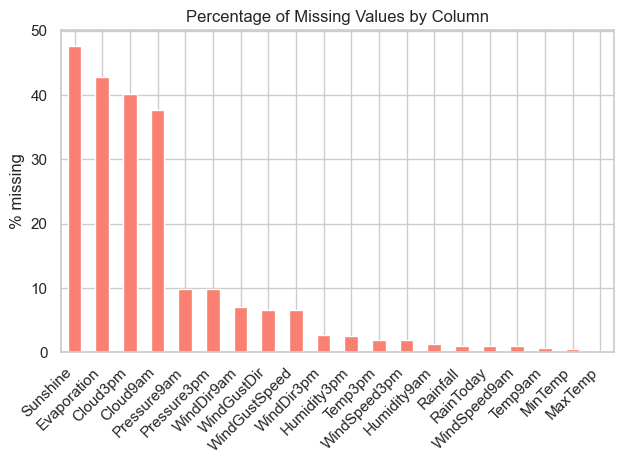

,%ค่าที่หาย
Sunshine,47.69
Evaporation,42.79
Cloud3pm,40.15
Cloud9am,37.74
Pressure9am,9.86
Pressure3pm,9.83
WindDir9am,7.04
WindGustDir,6.56
WindGustSpeed,6.52
WindDir3pm,2.66


In [43]:
missing = (df.isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]

plt.Figure(figsize=(10, 6))
missing.plot(kind='bar', color='salmon')
plt.title("Percentage of Missing Values by Column")
plt.ylabel("% missing")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

missing.round(2).to_frame("%ค่าที่หาย")

> **ตัดสินใจ:** แม้ `Sunshine` จะหายเกือบ 50% แต่เราจะ **ไม่ลบคอลัมน์** และจะเติมด้วยค่า median ในขั้นที่ 6
> (ทำหลังแบ่ง Train/Test เพื่อป้องกัน Data Leakage) — ในงานจริงอาจทดลองทั้งแบบลบและไม่ลบ แล้วเทียบผล

### 4.5 จำนวนหมวดหมู่ในแต่ละตัวแปร Categorical (Cardinality)
หากมีจำนวนหมวดหมู่มาก การทำ One-Hot Encoding จะสร้างคอลัมน์จำนวนมาก

In [44]:
for col in categorical:
    print(f"{col:13s} have {df[col].nunique():5d}")

Date          have  3436
Location      have    49
WindGustDir   have    16
WindDir9am    have    16
WindDir3pm    have    16
RainToday     have     2
RainTomorrow  have     2


> **ข้อสังเกต:** `Date` มีกว่า 3,000 ค่า (เพราะเป็นวันที่) → **ไม่ควรทำ One-Hot Encoding โดยตรง** ต้องแยกเป็นปี/เดือน/วันก่อน

### 4.6 Feature Engineering: แยกวันที่เป็น ปี / เดือน / วัน
`Month` น่าจะมีประโยชน์ เพราะฤดูกาลมีผลต่อฝน

In [45]:
df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df = df.drop(columns='Date')

In [46]:
df[['Year','Month','Day']].head()

,Year,Month,Day
0,2008,12,1
1,2008,12,2
2,2008,12,3
3,2008,12,4
4,2008,12,5


---
# ขั้นที่ 5: EDA & Visualization

### 5.1 ความสมดุลของ Target (Class Balance)

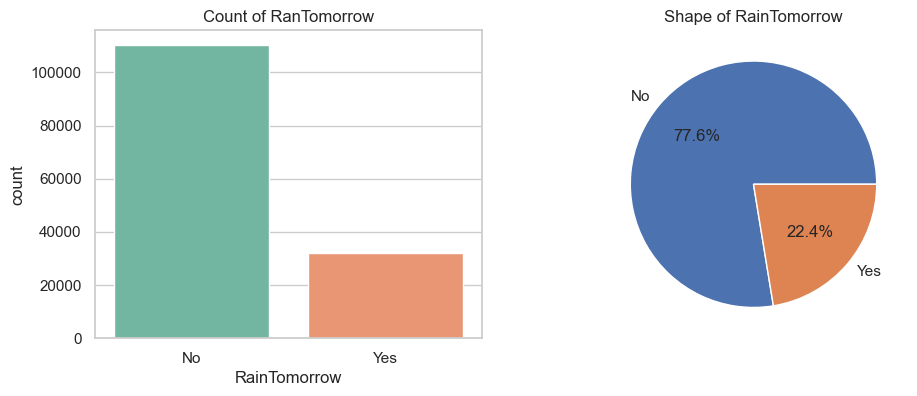

In [47]:
fig, ax = plt.subplots(1,2,figsize=(11,4))
sns.countplot(x='RainTomorrow', data=df,ax=ax[0],palette='Set2', hue='RainTomorrow', legend=False)
ax[0].set_title("Count of RanTomorrow")
df['RainTomorrow'].value_counts().plot(kind='pie', autopct='%1.1f%%',ax=ax[1],color=["#a4ec6c","#f4a582"])
ax[1].set_ylabel('')
ax[1].set_title('Shape of RainTomorrow')
plt.show()


> **ข้อมูลไม่สมดุล (Imbalanced):** วันฝนไม่ตก ~78% ฝนตก ~22%
> หากทำนายว่า "ไม่ตก" ทุกวัน จะได้ Accuracy ≈ 78% ทันทีโดยไม่ต้องมีโมเดล → เรียกว่า **Null Accuracy**
> ดังนั้นโมเดลต้องได้ **มากกว่า 78%** ถึงจะมีประโยชน์ และต้องดู Precision/Recall ประกอบด้วย

### 5.2 ตรวจ Outlier ด้วย Boxplot และ Histogram

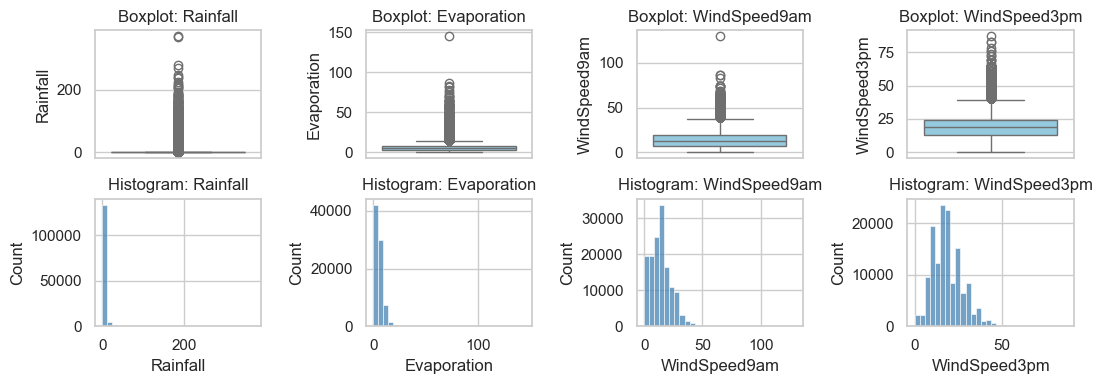

In [49]:
outlier_cols = ['Rainfall', 'Evaporation', 'WindSpeed9am','WindSpeed3pm']
fig, axes = plt.subplots(2,4,figsize=(11,4))
for i , col in enumerate(outlier_cols):
    sns.boxplot(y=df[col], ax=axes[0,i],color='skyblue')
    axes[0,i].set_title(f"Boxplot: {col}")
    sns.histplot(df[col], bins=30, ax=axes[1,i],color='steelblue')
    axes[1,i].set_title(f"Histogram: {col}")
plt.tight_layout()
plt.show()

> **ข้อสังเกต:** ทั้ง 4 ตัวมีจุดนอกกล่องจำนวนมาก และ Histogram เบ้ขวา → ต้องจัดการ Outlier

### 5.3 คำนวณขอบเขต Outlier ด้วย IQR
สูตร: `IQR = Q3 − Q1`, ขอบบน = `Q3 + k × IQR`
- ปกติ `k = 1.5` แต่ข้อมูลนี้เบ้มาก จึงใช้ `k = 3` (Extreme outlier) ตามต้นฉบับ เพื่อไม่ตัดข้อมูลมากเกินไป

In [56]:
for col in outlier_cols:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3-q1
    upper = q3 + 3 * iqr
    n_out = (df[col]>upper).sum()
    print(f"{col:13s} Q1={q1:6.1f} Q3={q3:6.1f} Upper={upper:6.1f} -> Outlier {n_out:6d} line({n_out/len(df):.1%})")

Rainfall      Q1=   0.0 Q3=   0.8 Upper=   3.2 -> Outlier  20462 line(14.4%)
Evaporation   Q1=   2.6 Q3=   7.4 Upper=  21.8 -> Outlier    471 line(0.3%)
WindSpeed9am  Q1=   7.0 Q3=  19.0 Upper=  55.0 -> Outlier    107 line(0.1%)
WindSpeed3pm  Q1=  13.0 Q3=  24.0 Upper=  57.0 -> Outlier     81 line(0.1%)


> **หมายเหตุ:** ตรงนี้คำนวณจากข้อมูลทั้งหมดเพื่อ **ดูภาพรวม** เท่านั้น ตอนจัดการจริง (ขั้นที่ 6) จะคำนวณขอบใหม่จาก **Train Set**

### 5.4 ความสัมพันธ์ระหว่างตัวแปรกับฝนในวันถัดไป

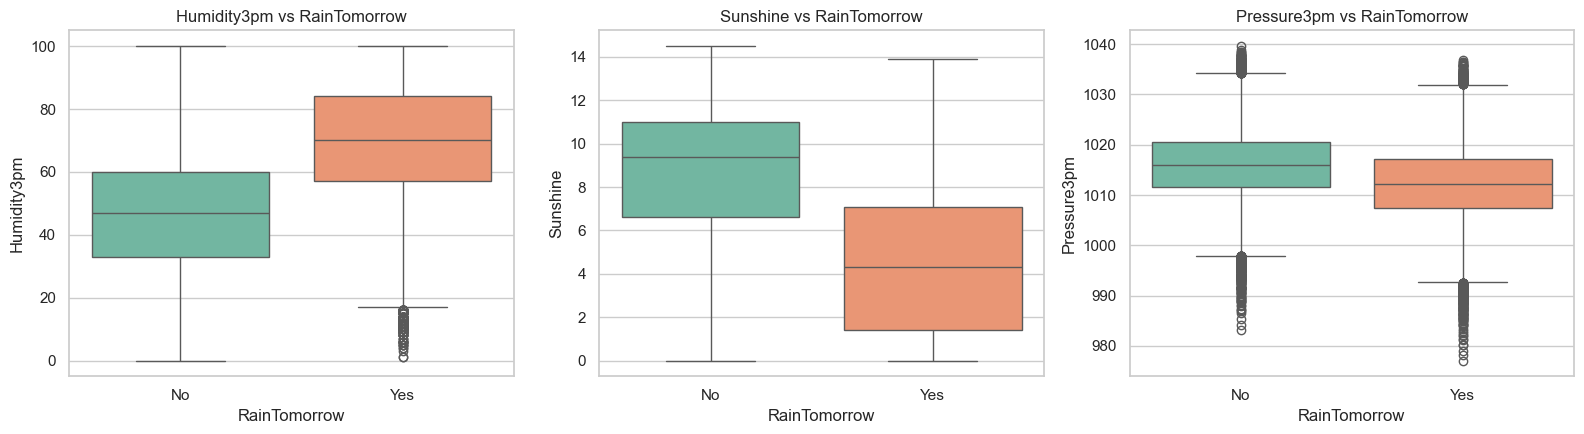

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(x='RainTomorrow', y='Humidity3pm', data=df, ax=axes[0], palette='Set2', hue='RainTomorrow', legend=False)
axes[0].set_title('Humidity3pm vs RainTomorrow')
sns.boxplot(x='RainTomorrow', y='Sunshine', data=df, ax=axes[1], palette='Set2', hue='RainTomorrow', legend=False)
axes[1].set_title('Sunshine vs RainTomorrow')
sns.boxplot(x='RainTomorrow', y='Pressure3pm', data=df, ax=axes[2], palette='Set2', hue='RainTomorrow', legend=False)
axes[2].set_title('Pressure3pm vs RainTomorrow')
plt.tight_layout()
plt.show()

> **ข้อสังเกต:** วันก่อนฝนตก: **ความชื้นตอนบ่ายสูงกว่า**, **แดดน้อยกว่า**, **ความกดอากาศต่ำกว่า** → ตัวแปรเหล่านี้น่าจะเป็น Feature ที่ดี

### 5.5 ความสัมพันธ์ระหว่างฝนวันนี้กับฝนวันถัดไป (Categorical × Categorical)

สัดส่วนฝนพรุ่งนี้ แยกตามฝนวันนี้:
RainTomorrow     No    Yes
RainToday                 
No            0.848  0.152
Yes           0.536  0.464


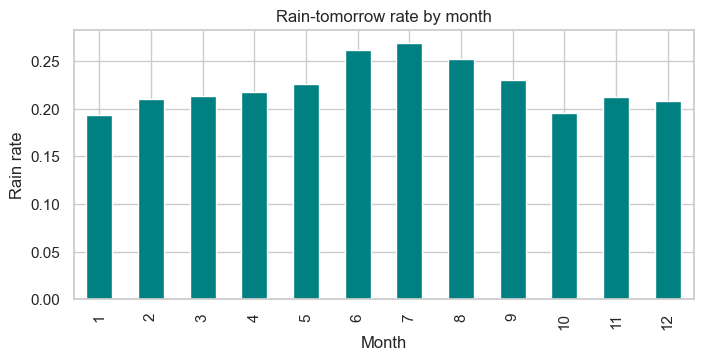

In [58]:
ct = pd.crosstab(df['RainToday'], df['RainTomorrow'], normalize='index').round(3)
print("สัดส่วนฝนพรุ่งนี้ แยกตามฝนวันนี้:")
print(ct)

monthly = df.groupby('Month')['RainTomorrow'].apply(lambda s: (s == 'Yes').mean())
plt.figure(figsize=(8, 3.5))
monthly.plot(kind='bar', color='teal')
plt.ylabel('Rain rate')
plt.title('Rain-tomorrow rate by month')
plt.show()

> **ข้อสังเกต:** ถ้าวันนี้ฝนตก โอกาสพรุ่งนี้ตกสูงขึ้นมาก (~46% เทียบกับ ~15%) และเดือนกลางปี (ฤดูหนาวของออสเตรเลีย) ฝนตกบ่อยกว่า

### 5.6 Correlation ระหว่างตัวแปรตัวเลข

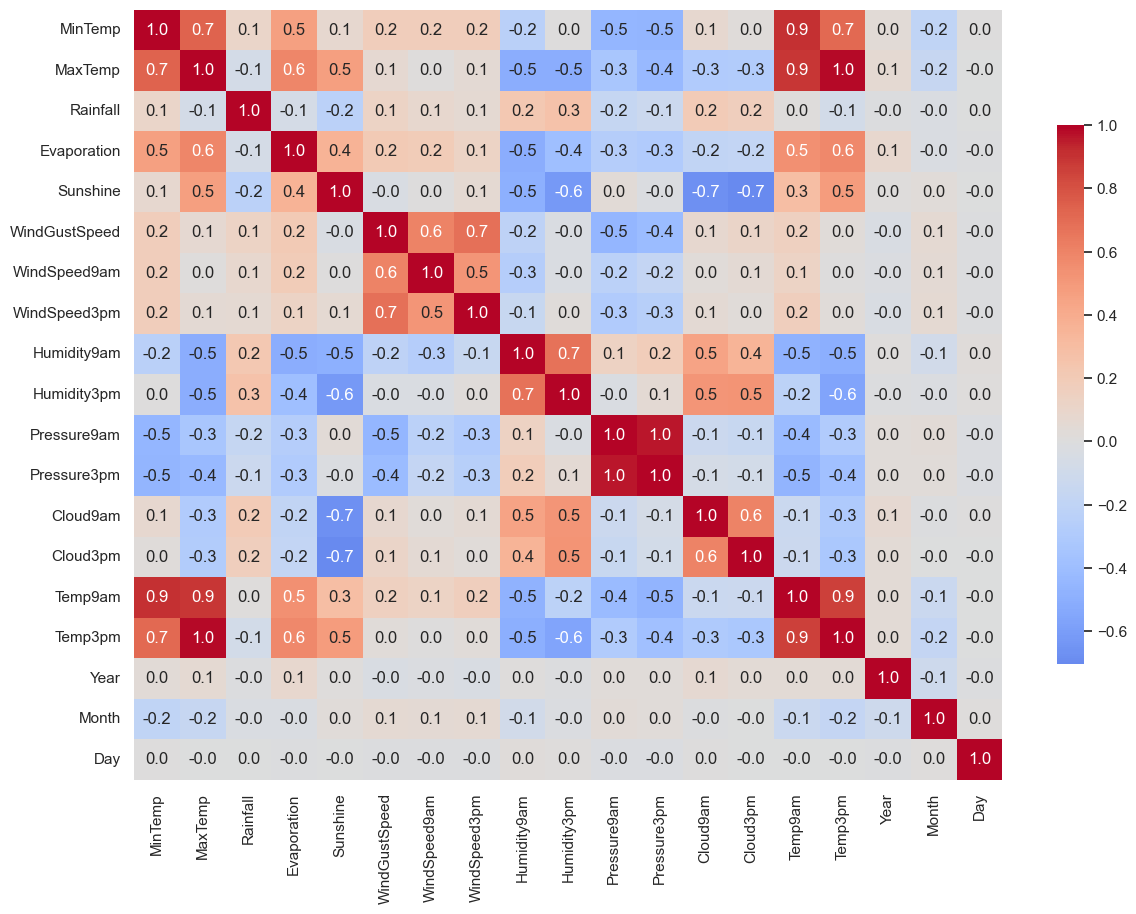

In [60]:
num_col = [c for c in df.columns if df[c].dtype != 'object']
plt.figure(figsize=(14,10))
sns.heatmap(df[num_col].corr(), annot=True, fmt='.1f', cmap='coolwarm', center=0,cbar_kws={'shrink':.7})
plt.show()

> **ข้อสังเกต:** คู่ที่สัมพันธ์กันสูงมาก เช่น `MaxTemp`–`Temp3pm`, `Pressure9am`–`Pressure3pm` (≈ 0.9+) แปลว่าข้อมูลซ้ำซ้อนกัน
> (Multicollinearity) — ไม่ทำให้ Tree เสีย แต่ทำให้ค่า coefficient ของ Logistic Regression ตีความยากขึ้น

---
# ขั้นที่ 6: เตรียมข้อมูลสำหรับโมเดล (Preprocessing)

### 6.1 แยก X (Feature) และ y (Target)
แปลง Target เป็นตัวเลข: `Yes → 1` (ฝนตก = คลาสที่สนใจ / Positive), `No → 0`

In [64]:
X = df.drop(columns='RainTomorrow')
y = (df['RainTomorrow'] == 'Yes').astype(int)
print("X", X.shape,"Y", y.shape)

X (142193, 24) Y (142193,)


### 6.2 แบ่ง Train / Test (80 / 20)
- `stratify=y` → ให้สัดส่วนฝนตก/ไม่ตกใน Train และ Test เท่ากัน (สำคัญมากกับข้อมูลไม่สมดุล)
- `random_state=0` → สุ่มแบบเดิมทุกครั้ง ผลลัพธ์จะเหมือนเดิม

In [66]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

### 6.3 จัดการ Outlier ด้วยการ "ตัดเพดาน" (Capping / Top-coding)
แทนที่จะลบแถวทิ้ง (เสียข้อมูล) เราจะ **แทนค่าที่เกินขอบบนด้วยค่าขอบบน** ขอบบนคำนวณจาก Train Set

> **ทำไมต้องทำก่อนเติมค่าหาย?** ถ้าเติม median ก่อน คอลัมน์ที่มีค่าหายจำนวนมาก (เช่น `Evaporation` หาย ~43%)
> จะมีค่า median ซ้ำกันจำนวนมาก ทำให้ IQR แคบผิดปกติ และตัดเพดานต่ำเกินไป (`quantile()` ข้ามค่า NaN ให้อยู่แล้ว)

In [67]:
X_train = X_train.copy()
X_test  = X_test.copy()

for col in outlier_cols:
    q1,q3 = X_train[col].quantile(0.25), X_train[col].quantile(0.75)
    upper = q3 + 3 * iqr
    X_train[col] = X_train[col].clip(upper=upper)
    X_test[col] = X_test[col].clip(upper=upper)
    

### 6.4 เติมค่าหาย (Imputation) ด้วยค่าจาก Train Set
| ชนิด | วิธี | เหตุผล |
|---|---|---|
| Numerical | **Median** | ทนต่อ Outlier มากกว่า Mean (ข้อมูลชุดนี้มี Outlier จำนวนมาก) |
| Categorical | **Mode** (ค่าที่พบบ่อยที่สุด) | ค่าข้อความหาค่าเฉลี่ยไม่ได้ |

In [68]:
categorical = [c for c in X_train.columns if X_train[c].dtype == 'object']
numerical   = [c for c in X_train.columns if X_train[c].dtype != 'object']

for col in numerical:
    median = X_train[col].median()                    # ← ค่าจาก Train เท่านั้น
    X_train[col] = X_train[col].fillna(median)
    X_test[col]  = X_test[col].fillna(median)

for col in categorical:
    mode = X_train[col].mode()[0]                     # ← ค่าจาก Train เท่านั้น
    X_train[col] = X_train[col].fillna(mode)
    X_test[col]  = X_test[col].fillna(mode)

print("ค่าหายที่เหลือ  Train:", X_train.isnull().sum().sum(), "  Test:", X_test.isnull().sum().sum())

ค่าหายที่เหลือ  Train: 0   Test: 0


### 6.5 แปลงข้อความเป็นตัวเลข (Encoding)
| คอลัมน์ | วิธี | เหตุผล |
|---|---|---|
| `RainToday` (Yes/No) | Map เป็น 1/0 | มีเพียง 2 ค่า ใช้คอลัมน์เดียวเพียงพอ |
| `Location`, `WindGustDir`, `WindDir9am`, `WindDir3pm` | **One-Hot Encoding** | ไม่มีลำดับ (ทิศ N ไม่ได้ "มากกว่า" ทิศ S) |

> **ข้อควรระวัง:** หลัง One-Hot ต้องทำให้ **คอลัมน์ของ Test ตรงกับ Train** ด้วย `reindex` (กันกรณีบางหมวดมีใน Train แต่ไม่มีใน Test)

In [69]:
X_train['RainToday'] = (X_train['RainToday'] == 'Yes').astype(int)
X_test['RainToday']  = (X_test['RainToday']  == 'Yes').astype(int)

onehot_cols = ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm']
X_train = pd.get_dummies(X_train, columns=onehot_cols, dtype=int)
X_test  = pd.get_dummies(X_test,  columns=onehot_cols, dtype=int)
X_test  = X_test.reindex(columns=X_train.columns, fill_value=0)   # จัดคอลัมน์ให้ตรงกัน

print("จำนวน Feature หลัง Encode:", X_train.shape[1])
X_train.iloc[:3, -8:]

จำนวน Feature หลัง Encode: 117


,WindDir3pm_S,WindDir3pm_SE,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW
103642,0,0,1,0,0,0,0,0
18697,1,0,0,0,0,0,0,0
99305,0,0,0,0,1,0,0,0


### 6.6 ปรับสเกล (Feature Scaling) ด้วย MinMaxScaler
แปลงทุกคอลัมน์ให้อยู่ช่วง 0–1 → Logistic Regression เรียนรู้ได้เร็วและเสถียรขึ้น (Tree ไม่จำเป็นต้อง Scale แต่ใช้ข้อมูลชุดเดียวกันได้ ไม่เสียหาย)

`fit_transform` กับ Train (เรียนค่า min/max) → `transform` กับ Test (ใช้ค่า min/max ของ Train)

In [70]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
feature_names = X_train.columns
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_names)
X_test  = pd.DataFrame(scaler.transform(X_test),      columns=feature_names)

X_train.describe().loc[['min', 'max']].iloc[:, :8]

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


> **ผลลัพธ์:** ข้อมูลพร้อมแล้ว: ไม่มีค่าหาย, ไม่มีข้อความ, สเกล 0–1, Train และ Test มีคอลัมน์ตรงกัน

---
# ขั้นที่ 7: โมเดลที่ 1 — Logistic Regression

### หลักการ
1. คำนวณคะแนน `z = w₁x₁ + w₂x₂ + … + b`
2. แปลงเป็นความน่าจะเป็นด้วย **Sigmoid**: `p = 1 / (1 + e⁻ᶻ)` (ได้ค่า 0–1 เสมอ)
3. ถ้า `p ≥ 0.5` → ทำนายว่า "ฝนตก" (1) มิฉะนั้นทำนายว่า "ไม่ตก" (0)

ค่า `0.5` เรียกว่า **Threshold** ปรับได้ (ดูข้อ 7.6)

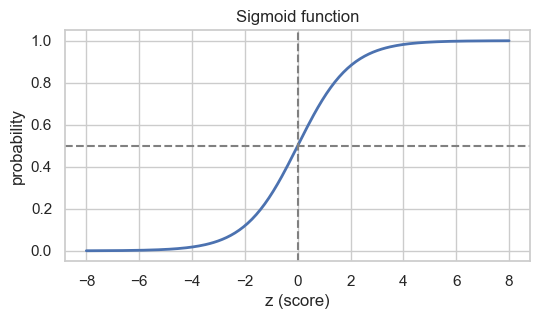

In [71]:
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 3))
plt.plot(z, 1 / (1 + np.exp(-z)), lw=2)
plt.axhline(0.5, ls='--', c='gray'); plt.axvline(0, ls='--', c='gray')
plt.xlabel('z (score)'); plt.ylabel('probability'); plt.title('Sigmoid function')
plt.show()

### 7.1 เทรนโมเดลและทำนาย

In [73]:
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression(solver='liblinear', random_state=0)
logreg.fit(X_train,y_train)

y_pred_lr = logreg.predict(X_test) 
y_prob_lr = logreg.predict_proba(X_test)[:,1]

pd.DataFrame({'Actual' : y_test.values[:8], "Predict":y_pred_lr[:8], "P(rain)": y_prob_lr[:8].round(3)})

,Actual,Predict,P(rain)
0,0,0,0.090
1,1,1,0.557
2,0,0,0.342
3,0,0,0.025
4,0,0,0.031
5,0,0,0.011
6,0,0,0.336
7,0,0,0.034


### 7.2 Accuracy: เทียบ Train vs Test และเทียบกับ Null Accuracy

In [78]:
from sklearn.metrics import accuracy_score
train_acc = logreg.score(X_train,y_train)
test_acc = accuracy_score(y_test, y_pred_lr)
null_acc = 1 - y_test.mean()

print(f"Train accuracy : {train_acc:.4f}")
print(f"Test accuracy : {test_acc:.4f}")
print(f"Null accuracy : {null_acc:.4f}")


Train accuracy : 0.8482
Test accuracy : 0.8495
Null accuracy : 0.7758


> **การตีความผล:** Train ≈ Test → **ไม่ Overfitting** และ Test (≈0.85) สูงกว่า Null accuracy (≈0.78) → โมเดลมีประโยชน์จริง

### 7.3 ทดลองปรับ Hyperparameter `C` (ความแรงของ Regularization)
- `C` เล็ก → ลงโทษ coefficient แรง → โมเดลเรียบง่าย (เสี่ยง Underfit)
- `C` ใหญ่ → ลงโทษน้อย → โมเดลซับซ้อน (เสี่ยง Overfit)

In [79]:
for C in [0.01, 1, 100]:
    m = LogisticRegression(C=C, solver='liblinear', random_state=0).fit(X_train, y_train)
    print(f"C={C:<6} Train={m.score(X_train, y_train):.4f}  Test={m.score(X_test, y_test):.4f}")

C=0.01   Train=0.8416  Test=0.8439
C=1      Train=0.8482  Test=0.8495
C=100    Train=0.8483  Test=0.8500


### 7.4 Confusion Matrix: รูปแบบการทำนายถูกและผิด

ใน scikit-learn: **แถว = ค่าจริง**, **คอลัมน์ = ค่าที่ทำนาย** (เรียงคลาส 0, 1)

| | ทำนาย 0 (ไม่ตก) | ทำนาย 1 (ตก) |
|---|---|---|
| **จริง 0 (ไม่ตก)** | **TN** | **FP** (เตือนฝนแต่ไม่ตก) |
| **จริง 1 (ตก)** | **FN** (ไม่เตือนแต่ฝนตก) | **TP** |

> **ข้อควรระวัง:** บางบทความ (รวมถึงต้นฉบับ) อ่านตำแหน่งสลับกัน ให้ยึดตารางนี้ หรือใช้ `cm.ravel()` ซึ่งคืนค่าเรียง `TN, FP, FN, TP` เสมอ

TN=20898  FP=1166  FN=3114  TP=3261


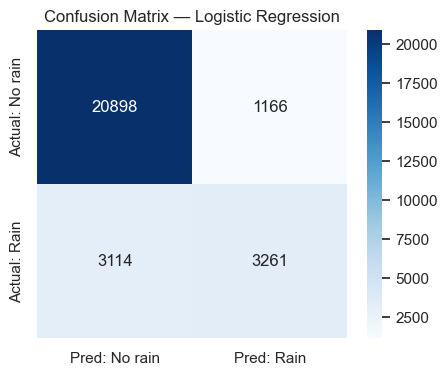

In [80]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)
TN, FP, FN, TP = cm.ravel()
print(f"TN={TN}  FP={FP}  FN={FN}  TP={TP}")

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred: No rain', 'Pred: Rain'], yticklabels=['Actual: No rain', 'Actual: Rain'])
plt.title('Confusion Matrix — Logistic Regression')
plt.show()

### 7.5 Metrics จาก Confusion Matrix

| Metric | สูตร | ความหมาย (โจทย์ฝน) |
|---|---|---|
| **Accuracy** | (TP+TN) / ทั้งหมด | ทำนายถูกกี่ % |
| **Precision** | TP / (TP+FP) | ที่บอกว่า "ฝนตก" ถูกจริงกี่ % |
| **Recall (Sensitivity)** | TP / (TP+FN) | วันฝนตกจริง ตรวจพบได้กี่ % |
| **Specificity** | TN / (TN+FP) | วันไม่ตกจริง ทำนายถูกกี่ % |
| **F1-score** | 2·P·R / (P+R) | ค่าเฉลี่ยแบบสมดุลของ Precision กับ Recall |

In [81]:
precision   = TP / (TP + FP)
recall      = TP / (TP + FN)
specificity = TN / (TN + FP)
f1          = 2 * precision * recall / (precision + recall)

print(f"Accuracy    : {(TP + TN) / cm.sum():.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1-score    : {f1:.4f}")

Accuracy    : 0.8495
Precision   : 0.7366
Recall      : 0.5115
Specificity : 0.9472
F1-score    : 0.6038


ใช้ `classification_report` ได้ผลเดียวกันในบรรทัดเดียว (แถว `1` คือคลาสฝนตก)

In [82]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_lr,target_names=['No rain (0)','NO rain (1)']))

              precision    recall  f1-score   support

 No rain (0)       0.87      0.95      0.91     22064
 NO rain (1)       0.74      0.51      0.60      6375

    accuracy                           0.85     28439
   macro avg       0.80      0.73      0.76     28439
weighted avg       0.84      0.85      0.84     28439



> **การตีความผล:** Precision ของฝนตกค่อนข้างดี (~0.72) แต่ **Recall เพียง ~0.51** → วันที่ฝนตกจริง โมเดลพลาดไปเกือบครึ่ง
> สาเหตุหลักคือข้อมูลไม่สมดุล โมเดลจึงเอนไปทาง "ไม่ตก" → แก้ได้ด้วยการลด Threshold

### 7.6 ปรับ Threshold: แลก Precision กับ Recall

In [83]:
from sklearn.metrics import precision_score, recall_score, f1_score

rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6]:
    pred_t = (y_prob_lr >= t).astype(int)
    rows.append({'Threshold': t,
                 'Accuracy':  accuracy_score(y_test, pred_t),
                 'Precision': precision_score(y_test, pred_t),
                 'Recall':    recall_score(y_test, pred_t),
                 'F1':        f1_score(y_test, pred_t)})
pd.DataFrame(rows).round(3)

,Threshold,Accuracy,Precision,Recall,F1
0,0.2,0.779,0.505,0.803,0.620
1,0.3,0.826,0.596,0.696,0.642
2,0.4,0.845,0.672,0.602,0.635
3,0.5,0.850,0.737,0.512,0.604
4,0.6,0.845,0.795,0.419,0.549


> **หมายเหตุ:** Threshold ต่ำลง → Recall สูงขึ้น (จับวันฝนตกได้มากขึ้น) แต่ Precision ลดลง (เตือนผิดบ่อยขึ้น)
> **เลือกตามธุรกิจ:** ถ้าการพลาดวันฝนตกมีต้นทุนสูง (เช่น จัดงานกลางแจ้ง) ให้ใช้ Threshold ต่ำลง

### 7.7 ROC Curve และ AUC
- ROC = กราฟ True Positive Rate (Recall) เทียบ False Positive Rate ที่ **ทุก Threshold**
- **AUC** = พื้นที่ใต้กราฟ: 1.0 = สมบูรณ์แบบ, 0.5 = เทียบเท่าการสุ่ม (เส้นทแยง)

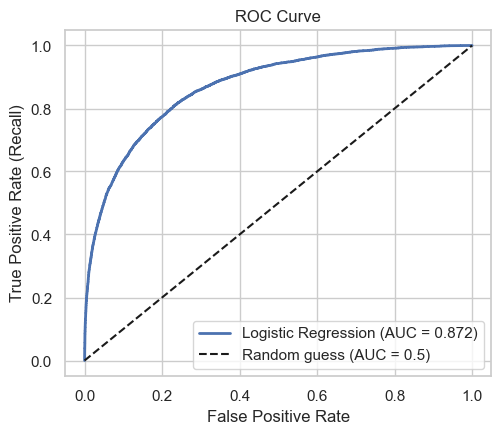

In [84]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, _ = roc_curve(y_test, y_prob_lr)
auc_lr = roc_auc_score(y_test, y_prob_lr)

plt.figure(figsize=(5.5, 4.5))
plt.plot(fpr, tpr, lw=2, label=f'Logistic Regression (AUC = {auc_lr:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess (AUC = 0.5)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve'); plt.legend(loc='lower right')
plt.show()

### 7.8 k-Fold Cross-Validation: ความเสถียรของผลลัพธ์
แบ่ง Train เป็น 5 ส่วน สลับกันเป็นชุดทดสอบ → ได้คะแนน 5 ค่า ถ้าใกล้กันแปลว่าโมเดลเสถียร

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_scores = cross_val_score(LogisticRegression(solver='liblinear', random_state=0), X_train, y_train, cv=kfold, scoring='accuracy')
print("Accuracy แต่ละ Fold:", cv_scores.round(4))
print(f"เฉลี่ย {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

### 7.9 หา `C` ที่ดีที่สุดด้วย GridSearchCV
GridSearchCV = ทดลองทุกค่าที่กำหนด × Cross-Validation แล้วเลือกค่าที่ดีที่สุดให้อัตโนมัติ (ใช้ Train เท่านั้น)

### 7.10 การวิเคราะห์ผล Logistic Regression

| ประเด็น | ผลลัพธ์ | การตีความ |
|---|---|---|
| ดีกว่า Baseline หรือไม่ | Test Acc **0.846** vs Null **0.776** | สูงกว่าการทำนายว่า "ไม่ตก" ทุกวันประมาณ 7 จุด (ส่วนต่างน้อยกว่าที่ตัวเลข 85% อาจทำให้เข้าใจ) |
| Overfit หรือไม่ | Train 0.849 vs Test 0.846 | แทบเท่ากัน → ไม่ Overfit |
| เสถียรหรือไม่ | CV 0.848 ± 0.003 | คะแนน 5 รอบแทบเท่ากัน |
| บอกว่า "ฝนตก" เชื่อได้เพียงใด? | Precision **0.72** | บอกว่าตก 4 ครั้ง ถูก ~3 ครั้ง |
| วันฝนตกจริงตรวจพบได้เพียงใด? | Recall **0.51** | จุดอ่อนหลัก: จากวันฝนตกจริง 6,375 วัน ตรวจพบ 3,242 / **พลาด 3,133 วัน** |
| วันไม่ตกทำนายถูกเพียงใด? | Specificity 0.94 | เตือนผิด (FP) เพียง 1,235 จาก 22,064 วัน |
| แยกสองคลาสได้ดีเพียงใด? | ROC-AUC **0.868** | ระดับดี (0.5 = เทียบเท่าการสุ่ม, 1.0 = สมบูรณ์แบบ) |
| `C` มีผลหรือไม่ | C = 0.01 → 0.840, C = 1 หรือ 100 → 0.846 | แทบไม่มีผล — โมเดลไม่ได้ Overfit จึงไม่ต้องพึ่ง Regularization มาก |
| ปรับ Threshold ช่วยหรือไม่ | Threshold 0.3 → Recall 0.69, Precision 0.59, **F1 0.64** (สูงสุด) | แลก Precision เล็กน้อย เพื่อจับวันฝนตกได้เพิ่ม ~18 จุด |

> **สรุป:** โมเดลเสถียรและไม่ Overfit, Precision ดี แต่ **Recall ต่ำเพราะข้อมูลไม่สมดุล** (ฝนตกเพียง 22%)
> ถ้าการพลาดวันฝนตกมีความเสียหายสูง ควรใช้ Threshold ≈ 0.3 แทน 0.5

---
# ขั้นที่ 8: โมเดลที่ 2 — Decision Tree

### หลักการ
สร้าง "ต้นไม้คำถาม Yes/No" เช่น *ความชื้นบ่าย > 70%?* → *แดด < 5 ชม.?* → ทำนาย
แต่ละจุดแยกเลือกคำถามที่ทำให้กลุ่มลูก **บริสุทธิ์ที่สุด** (Gini impurity ต่ำสุด)

**จุดอ่อน:** ถ้าไม่จำกัดความลึก ต้นไม้จะ "จำ" ข้อมูล Train ได้หมด → **Overfitting**

### 8.1 ทดลอง: ไม่จำกัดความลึก

### 8.2 การเลือกความลึกของต้นไม้ (Train vs Test)

> **ข้อสังเกต:** ยิ่งลึก Train ยิ่งสูง แต่ Test ขึ้นถึงจุดหนึ่ง (~8) แล้ว **ลดลง** = เริ่ม Overfit

### 8.3 เลือก `max_depth` อย่างถูกวิธีด้วย GridSearchCV
(ไม่ควรเลือกจากกราฟ Test ข้างบน เพราะเท่ากับใช้ Test ในการตัดสินใจ)

### 8.4 ดูหน้าตาต้นไม้ (3 ชั้นแรก) และ Feature Importance

> **ข้อสังเกต:** `Humidity3pm` สำคัญที่สุด สอดคล้องกับที่เห็นใน EDA (ข้อ 5.4)

### 8.5 ผลบน Test Set

### 8.6 การวิเคราะห์ผล Decision Tree

| ประเด็น | ผลลัพธ์ | การตีความ |
|---|---|---|
| ไม่จำกัดความลึกเป็นอย่างไร? | ลึก 42 ชั้น, Train **1.000** vs Test **0.790** | Overfit หนัก — จำข้อมูล Train ได้หมด และสูงกว่า Null accuracy (0.776) เพียงเล็กน้อย |
| หลังจูนด้วย GridSearchCV | `max_depth=10`, `min_samples_leaf=50` → Train 0.854 vs Test **0.837** | ช่องว่างเหลือ ~1.6 จุด แก้ Overfit ได้ |
| Precision / Recall / F1 (ฝนตก) | 0.70 / 0.49 / 0.57 | Recall ต่ำแบบเดียวกับ Logistic Regression และต่ำกว่าเล็กน้อยทุกตัว |
| ROC-AUC | **0.850** | ต่ำสุดในสามโมเดล |
| ใช้ Feature อะไรตัดสิน? | `Humidity3pm` สำคัญ ~0.63 (เกินครึ่ง) | ต้นไม้ต้นเดียวพึ่ง Feature เดียวเป็นหลัก |

> **สรุป:** แม่นน้อยที่สุดในสามโมเดล แต่ **ตีความง่ายที่สุด** — วาดเป็นกฎ "ถ้า...แล้ว..." ให้คนทั่วไปอ่านได้
> และเป็นตัวอย่างชัดเจนที่สุดว่า **การจำกัดความลึกสำคัญมาก** กับโมเดล Tree

---
# ขั้นที่ 9: โมเดลที่ 3 — Random Forest

### หลักการ
สร้าง Decision Tree **หลายร้อยต้น** แต่ละต้นเห็นข้อมูลและ Feature ต่างส่วนกัน (สุ่ม) แล้วให้ **โหวต** คำตอบ
→ ความผิดพลาดของแต่ละต้นหักล้างกัน ได้ผลแม่นและเสถียรกว่าต้นไม้ต้นเดียว (ลด Overfitting)

| Hyperparameter | ความหมาย | ค่าที่ใช้ |
|---|---|---|
| `n_estimators` | จำนวนต้นไม้ | 100 |
| `max_depth` | ความลึกสูงสุดของแต่ละต้น | 20 (กันไม่ให้ต้นไม้ใหญ่เกินไป) |
| `n_jobs=-1` | ใช้ CPU ทุก core | เร็วขึ้น |

> **ข้อสังเกต:** Train สูงกว่า Test พอสมควร (Overfit บ้าง) แต่ **Test ยังสูงกว่า Decision Tree ต้นเดียว** — นี่คือจุดเด่นของ Ensemble

### 9.1 ผลบน Test Set

### 9.2 การวิเคราะห์ผล Random Forest

| ประเด็น | ผลลัพธ์ | การตีความ |
|---|---|---|
| แม่นเพียงใด? | Test Acc **0.853** | สูงสุดในสามโมเดล |
| Overfit หรือไม่ | Train 0.943 vs Test 0.853 | ช่องว่าง ~9 จุด Overfit บ้าง แต่ Test ยังดีที่สุด (แต่ละต้นลึกได้ถึง 20 ชั้น) |
| บอกว่า "ฝนตก" เชื่อได้เพียงใด? | Precision **0.78** | สูงสุด — เตือนผิดน้อยที่สุด |
| วันฝนตกจริงตรวจพบได้เพียงใด? | Recall **0.48** | ต่ำสุดเล็กน้อย — โมเดลมีแนวโน้มทำนายว่าฝนตกเฉพาะเมื่อมีความมั่นใจสูง |
| F1 | 0.595 | ใกล้เคียง Logistic Regression (0.597) |
| ROC-AUC | **0.878** | สูงสุด — แยกวันฝนตก/ไม่ตกได้ดีที่สุด |
| ใช้ Feature อะไรตัดสิน? | `Humidity3pm` ~0.17 ที่เหลือกระจาย ~0.04–0.05 | ใช้ข้อมูลหลายตัวร่วมกัน ไม่พึ่งตัวเดียวแบบ Decision Tree |

> **สรุป:** แม่นที่สุดทั้ง Accuracy, Precision และ AUC เพราะเฉลี่ยคำตอบจากต้นไม้ 100 ต้น
> แต่ Recall ยังต่ำ — ทดลองลด Threshold แบบข้อ 7.6 ได้เช่นกัน (`rf.predict_proba(X_test)[:, 1] >= 0.3`)

---
# ขั้นที่ 10: เปรียบเทียบ 3 โมเดลและเลือกโมเดลที่ดีที่สุด

### 10.1 ตารางเปรียบเทียบ Metrics (บน Test Set)

### 10.2 ROC Curve ของทั้ง 3 โมเดล

### 10.3 Confusion Matrix ของทั้ง 3 โมเดล

### 10.4 สรุปผลการเปรียบเทียบ

| โมเดล | Test Acc | Precision | Recall | F1 | ROC-AUC | Overfit? | จุดเด่น |
|---|---|---|---|---|---|---|---|
| Logistic Regression | 0.846 | 0.72 | **0.51** | **0.597** | 0.868 | ไม่ | เสถียร เร็ว อธิบายง่าย, F1/Recall สูงสุด |
| Decision Tree | 0.837 | 0.70 | 0.49 | 0.574 | 0.850 | ไม่ (หลังปรับ Hyperparameter) | ตีความง่ายที่สุด |
| Random Forest | **0.853** | **0.78** | 0.48 | 0.595 | **0.878** | เล็กน้อย | แม่นที่สุด, AUC สูงสุด |

**ข้อค้นพบหลัก**
1. **ทุกโมเดลให้ผลดีกว่า Baseline** (Null accuracy 0.776) แต่ส่วนต่างเพียง 6–8 จุด → ต้องรายงาน Null accuracy ด้วยทุกครั้ง
2. **ทั้งสามโมเดลแม่นใกล้เคียงกันมาก** (Accuracy ห่างกันไม่ถึง 2 จุด) โมเดลที่ซับซ้อนขึ้นไม่ได้ช่วยมาก
3. **จุดอ่อนร่วม = Recall ≈ 0.5** มาจากข้อมูลไม่สมดุล ไม่ใช่จากโมเดล → แก้ด้วยการลด Threshold หรือ `class_weight='balanced'`
4. **ความชื้นตอนบ่าย (`Humidity3pm`)** เป็นตัวทำนายที่สำคัญที่สุดในทุกโมเดล ตรงกับ EDA

**คำแนะนำ**
- ต้องการความแม่นสูงสุด → **Random Forest**
- ต้องการโมเดลเรียบง่าย อธิบายได้ ใช้ทรัพยากรน้อย → **Logistic Regression** (เสียความแม่นไปเพียง ~0.7 จุด)
- ใช้จริงควรปรับ Threshold ≈ 0.3 เพื่อให้จับวันฝนตกได้มากขึ้น

> **ตัวอย่างการเขียนสรุปผลในข้อสอบ:**
> *"เลือก Random Forest เพราะได้ Accuracy (0.853) และ ROC-AUC (0.878) สูงสุดบน Test Set และสูงกว่า Null accuracy (0.776)
> แม้ Train/Test ต่างกัน ~9 จุดแต่ Test ยังดีที่สุด ข้อจำกัดคือ Recall ของวันฝนตกเพียง 0.48 เนื่องจากข้อมูลไม่สมดุล
> หากต้องการลดการพลาดวันฝนตก ควรลด Threshold หรือใช้ class_weight='balanced'"*
>
> โครงที่ใช้: (1) เลือกโมเดลอะไร (2) ตัวเลขที่ใช้ตัดสิน (3) เหตุผล (4) ข้อจำกัดและสิ่งที่จะปรับต่อ

---
## รายการตรวจสอบสำหรับการสอบ (Checklist)
- [ ] ลบแถวที่ Target หาย / ตรวจข้อมูลซ้ำ
- [ ] ดูสัดส่วน Target และคำนวณ Null accuracy
- [ ] **Split ก่อน** แล้วค่อยจัด Outlier / เติมค่าหาย / Scale ด้วยค่าจาก Train
- [ ] Encode ข้อความ และจัดคอลัมน์ Test ให้ตรง Train
- [ ] เทรนอย่างน้อย 2–3 โมเดล เทียบ Train vs Test (เช็ค Overfit)
- [ ] รายงาน Confusion Matrix, Precision, Recall, F1, ROC-AUC
- [ ] ใช้ Cross-Validation / GridSearchCV เลือก Hyperparameter (ไม่ใช้ Test)
- [ ] สรุปเลือกโมเดลพร้อมเหตุผล

## แบบฝึกหัด
1. ทดลองเพิ่ม `class_weight='balanced'` ให้ Logistic Regression แล้วดู Recall เปลี่ยนไปอย่างไร
2. เพิ่มโมเดลที่ 4: `KNeighborsClassifier(n_neighbors=15)` แล้วเพิ่มลงในตารางเปรียบเทียบ